In [1]:
!pip install -q ucimlrepo imbalanced-learn shap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Download dataset from UCI
dataset = fetch_ucirepo(id=144)

X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()

# Standardize target labels:
# 1 = Good risk -> 0
# 2 = Bad risk  -> 1
y = y.astype(str).str.strip().replace({
    "1": 0,
    "2": 1,
    "good": 0,
    "bad": 1
}).astype(int)

# Rename columns for easier interpretation
X.columns = [f"Attribute{i}" for i in range(1, 21)]

df = X.copy()
df["Credit_Risk"] = y

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nTarget distribution:")
print(y.value_counts().rename({
    0: "Good Risk",
    1: "Bad Risk"
}))

print("\nStatistical summary:")
display(X.describe(include="all").T)

Dataset shape: (1000, 21)

First five records:


/tmp/ipykernel_2718/2683728430.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = y.astype(str).str.strip().replace({


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Credit_Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribute18  1000 non-null   int64 
 18  Attribute19  1000 non-null   object
 19  Attrib

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Attribute1,1000,4,A14,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute2,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Attribute3,1000,5,A32,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute4,1000,10,A43,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute5,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Attribute6,1000,5,A61,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute7,1000,5,A73,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute8,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
Attribute9,1000,4,A93,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute10,1000,3,A101,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


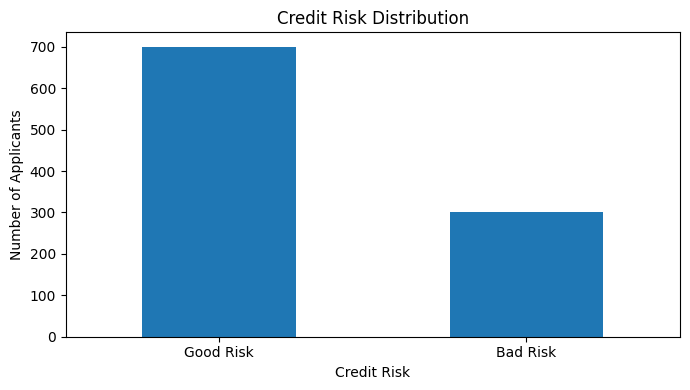

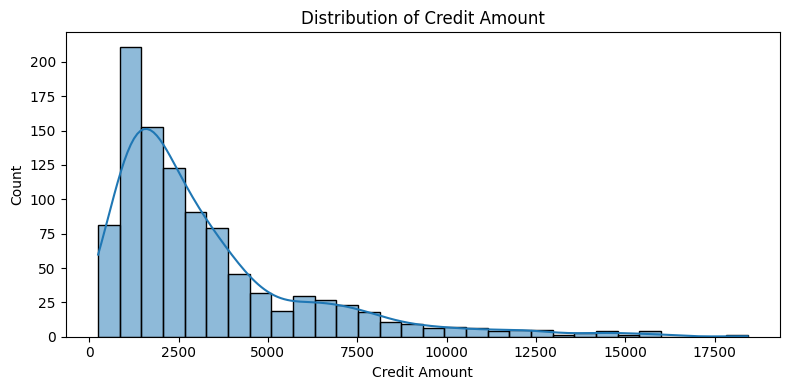

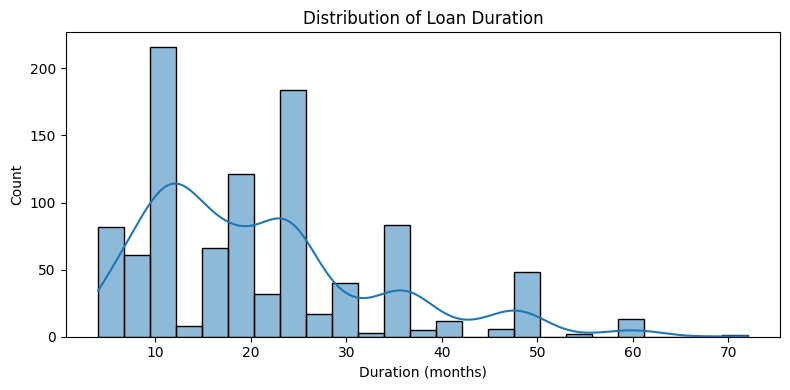

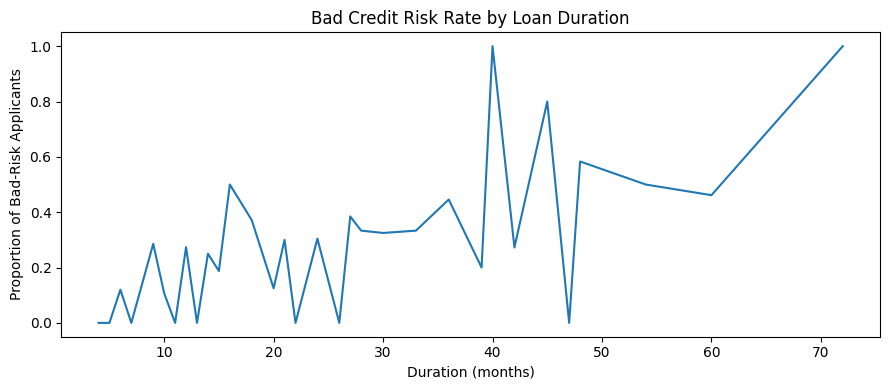

In [3]:
# 1. Good vs bad credit-risk distribution
risk_counts = y.map({
    0: "Good Risk",
    1: "Bad Risk"
}).value_counts()

plt.figure(figsize=(7, 4))
risk_counts.plot(kind="bar")
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Credit amount distribution (Attribute5)
credit_amount = pd.to_numeric(X["Attribute5"])

plt.figure(figsize=(8, 4))
sns.histplot(credit_amount, bins=30, kde=True)
plt.title("Distribution of Credit Amount")
plt.xlabel("Credit Amount")
plt.tight_layout()
plt.show()

# 3. Loan duration distribution (Attribute2)
plt.figure(figsize=(8, 4))
sns.histplot(X["Attribute2"], bins=25, kde=True)
plt.title("Distribution of Loan Duration")
plt.xlabel("Duration (months)")
plt.tight_layout()
plt.show()

# 4. Bad-risk rate by loan duration
eda_df = X.copy()
eda_df["Bad_Risk"] = y

duration_risk = eda_df.groupby("Attribute2")["Bad_Risk"].mean()

plt.figure(figsize=(9, 4))
duration_risk.plot()
plt.title("Bad Credit Risk Rate by Loan Duration")
plt.xlabel("Duration (months)")
plt.ylabel("Proportion of Bad-Risk Applicants")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify categorical and numerical features
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = [
    col for col in X.columns if col not in categorical_cols
]

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Stratified split maintains the original class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

Categorical features: ['Attribute1', 'Attribute3', 'Attribute4', 'Attribute6', 'Attribute7', 'Attribute9', 'Attribute10', 'Attribute12', 'Attribute14', 'Attribute15', 'Attribute17', 'Attribute19', 'Attribute20']
Numerical features: ['Attribute2', 'Attribute5', 'Attribute8', 'Attribute11', 'Attribute13', 'Attribute16', 'Attribute18']
Training records: 800
Testing records: 200

Training class distribution:
class
0    560
1    240
Name: count, dtype: int64


In [6]:
from imblearn.over_sampling import SMOTE

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for SMOTE
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

print("\nBalanced training shape:", X_train_balanced.shape)

Before SMOTE:
class
0    560
1    240
Name: count, dtype: int64

After SMOTE:
class
1    560
0    560
Name: count, dtype: int64

Balanced training shape: (1120, 61)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        class_weight=None,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    # Train on the balanced training data
    model.fit(X_train_balanced, y_train_balanced)

    # Predict on the original, untouched test data
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    from sklearn.metrics import (
        accuracy_score, precision_score,
        recall_score, f1_score, roc_auc_score
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).set_index("Model")

print("Model Comparison:")
display(results_df.round(4))

Model Comparison:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.745,0.5529,0.7833,0.6483,0.7967
Decision Tree,0.655,0.4430,0.5833,0.5036,0.6400
Random Forest,0.765,0.6383,0.5000,0.5607,0.7874


Best model by F1 score: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

   Good Risk       0.89      0.73      0.80       140
    Bad Risk       0.55      0.78      0.65        60

    accuracy                           0.74       200
   macro avg       0.72      0.76      0.72       200
weighted avg       0.79      0.74      0.75       200



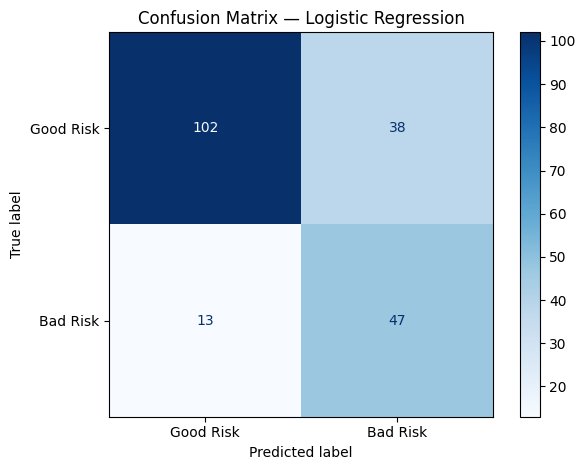

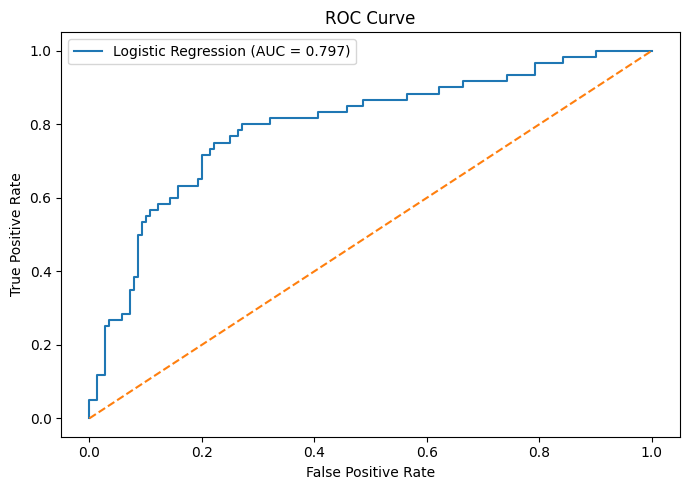

In [8]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# Select the model with the highest test F1 score
best_model_name = results_df["F1 Score"].idxmax()
best_model = trained_models[best_model_name]

print("Best model by F1 score:", best_model_name)

y_pred_best = best_model.predict(X_test_processed)
y_prob_best = best_model.predict_proba(X_test_processed)[:, 1]

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=["Good Risk", "Bad Risk"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    labels=[0, 1],
    display_labels=["Good Risk", "Bad Risk"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr, tpr,
    label=f"{best_model_name} (AUC = {auc(fpr, tpr):.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

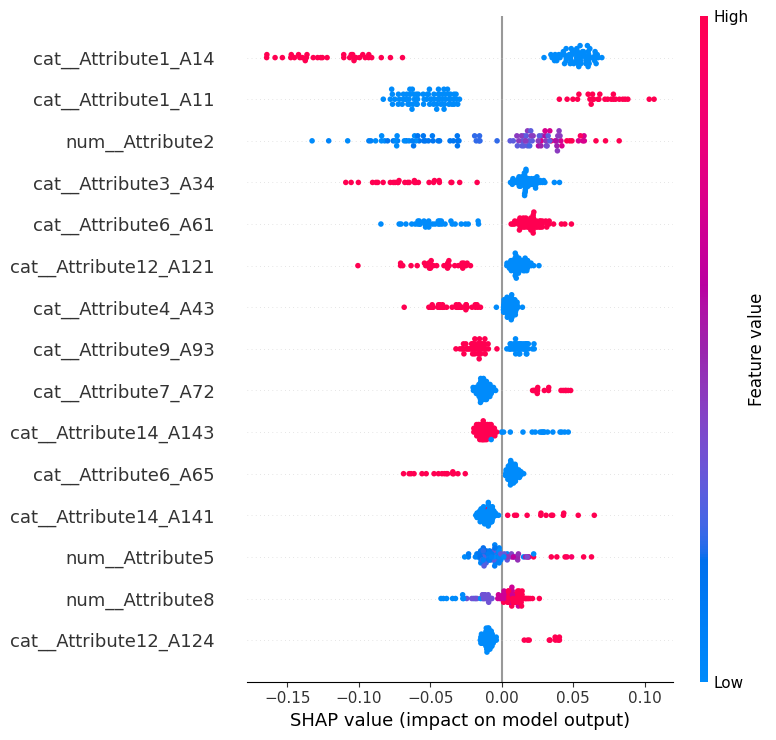

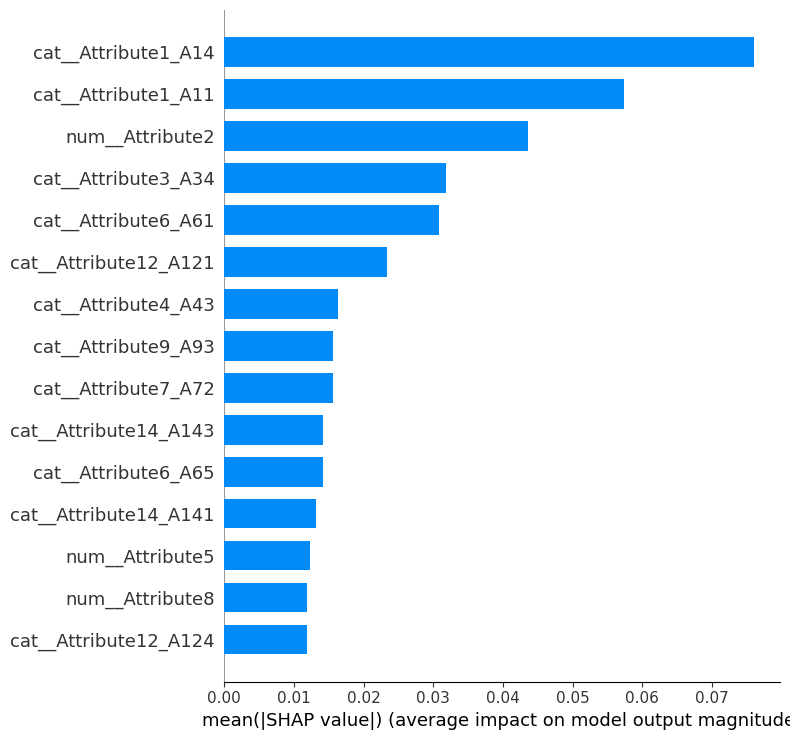

In [9]:
import shap

# Use the trained Random Forest model
rf_model = trained_models["Random Forest"]

# Get readable feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# SHAP background sample and test sample
background = X_train_balanced[
    :min(100, len(X_train_balanced))
]

explain_data = X_test_processed[
    :min(100, len(X_test_processed))
]

# TreeExplainer for Random Forest
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(explain_data)

# Handle different SHAP versions for binary classification
if isinstance(shap_values, list):
    # Older SHAP versions: list of arrays by class
    bad_risk_shap = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Some newer versions: samples x features x classes
    bad_risk_shap = shap_values[:, :, 1]
else:
    # Binary output represented as a 2D array
    bad_risk_shap = shap_values

# Summary plot: global feature importance
shap.summary_plot(
    bad_risk_shap,
    explain_data,
    feature_names=feature_names,
    max_display=15,
    show=True
)

# Bar plot: average absolute SHAP value
shap.summary_plot(
    bad_risk_shap,
    explain_data,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15,
    show=True
)

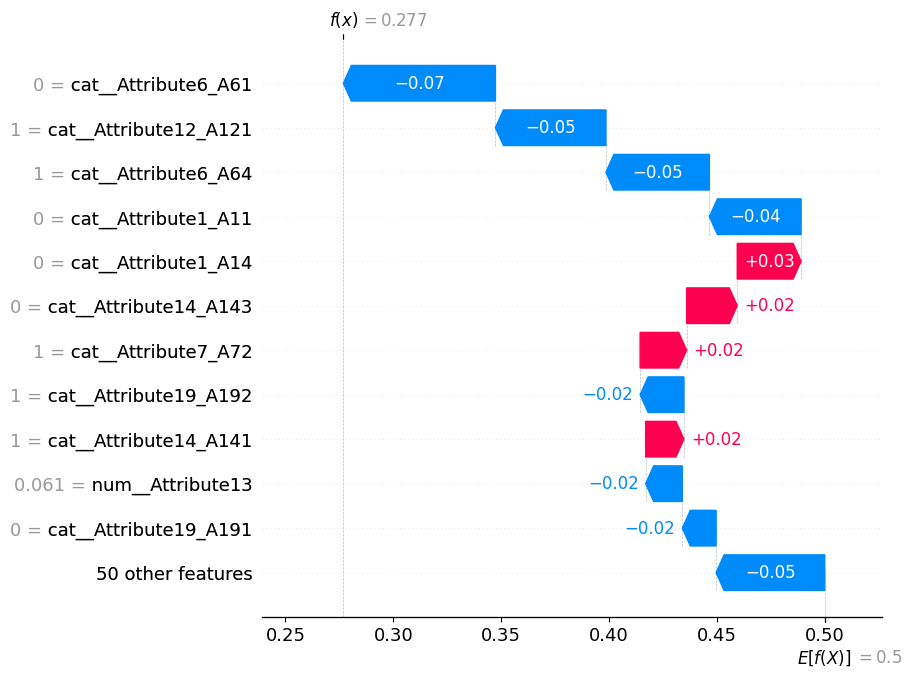

Actual class: Good Risk
Predicted class: Good Risk
Predicted probability of bad risk: 0.3449


In [10]:
# Explain the first test applicant
i = 0

# Obtain SHAP values for the selected applicant
if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_value = np.asarray(explainer.expected_value).flatten()[1]
else:
    base_value = explainer.expected_value

if isinstance(shap_values, list):
    individual_shap = shap_values[1][i]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    individual_shap = shap_values[i, :, 1]
else:
    individual_shap = shap_values[i]

# Waterfall plot
explanation = shap.Explanation(
    values=individual_shap,
    base_values=base_value,
    data=explain_data[i],
    feature_names=feature_names
)

shap.plots.waterfall(explanation, max_display=12)

print("Actual class:",
      "Bad Risk" if y_test.iloc[i] == 1 else "Good Risk")

print("Predicted class:",
      "Bad Risk" if y_pred_best[i] == 1 else "Good Risk")

print("Predicted probability of bad risk:",
      round(y_prob_best[i], 4))

In [11]:
# Save model comparison
results_df.to_csv("credit_risk_model_comparison.csv")

# Save actual labels, predictions, and predicted probabilities
predictions_df = pd.DataFrame({
    "Actual_Risk": y_test.map({
        0: "Good Risk",
        1: "Bad Risk"
    }).values,
    "Predicted_Risk": pd.Series(
        y_pred_best, index=y_test.index
    ).map({
        0: "Good Risk",
        1: "Bad Risk"
    }).values,
    "Bad_Risk_Probability": y_prob_best
}, index=y_test.index)

predictions_df.to_csv("credit_risk_predictions.csv", index=False)

print("Files saved successfully:")
print("1. credit_risk_model_comparison.csv")
print("2. credit_risk_predictions.csv")

# Download files in Google Colab
from google.colab import files

files.download("credit_risk_model_comparison.csv")
files.download("credit_risk_predictions.csv")

Files saved successfully:
1. credit_risk_model_comparison.csv
2. credit_risk_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>